# Instructor Coordinate-Projection Benchmark Plots

One plot per cell. Each cell calls a single function from `figures.py`, which
loads a results JSON and returns a matplotlib figure, followed by a markdown
cell explaining what it shows. Run the drivers first if the JSON files are
missing:

```bash
python -m benchmark.run_benchmark --pinn-seeds 0 1 2 --plot
python -m benchmark.experiments.instructor_coordinate_projection.run_comparison --steps 6000 --seeds 0 1 2
python -m benchmark.experiments.instructor_coordinate_projection.run_step_sweep --steps 6000 20000 50000
```

In [1]:
import sys
from pathlib import Path

SPINN_ROOT = Path.cwd()
while SPINN_ROOT.name != "SPINN" and SPINN_ROOT != SPINN_ROOT.parent:
    SPINN_ROOT = SPINN_ROOT.parent
if str(SPINN_ROOT) not in sys.path:
    sys.path.insert(0, str(SPINN_ROOT))

from benchmark.experiments.instructor_coordinate_projection import figures

## PINN vs. classical FEM

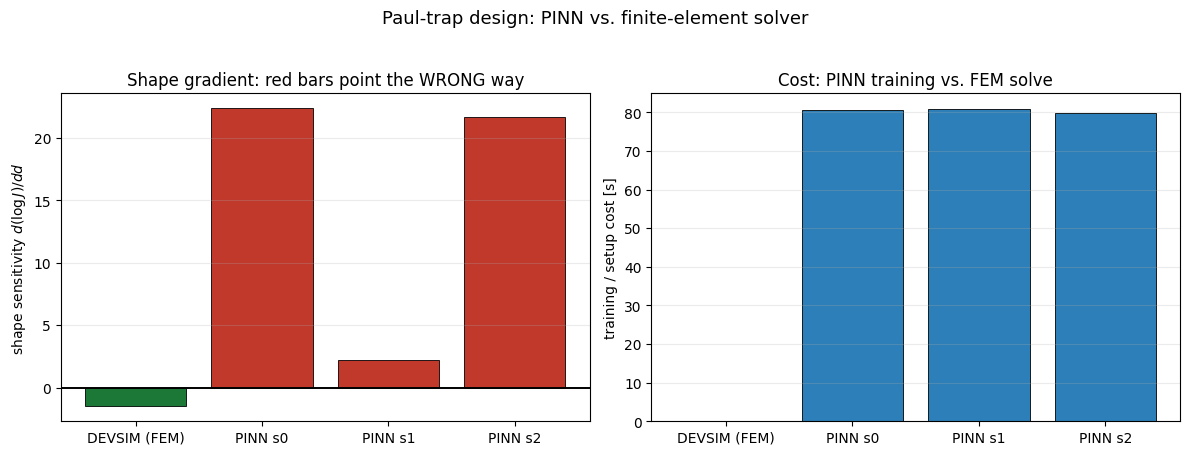

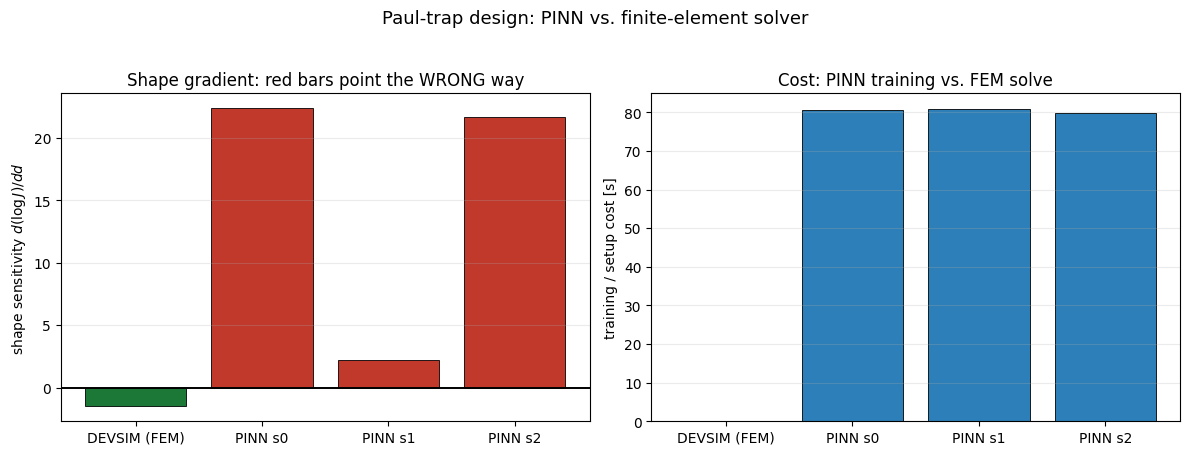

In [2]:
figures.plot_pinn_vs_fem()

**What it shows.** Left: the shape sensitivity `d(log J)/dd` for each method.
DEVSIM (FEM) is the ground-truth reference; a bar is green if its sign agrees
with DEVSIM and red if it points the wrong way. Right: the one-time training /
setup cost.

**Result.** At the original 6000-step budget the PINN bars are red: the PINN
reports the wrong gradient sign, so a shape optimizer driven by it would move the
geometry the wrong direction, and it costs far more to set up than the FEM solve.
This is the result that motivated the two diagnostics below. The verdict is
revised by the step-count sweep at the end of the notebook.

## Instructor map diagnostics

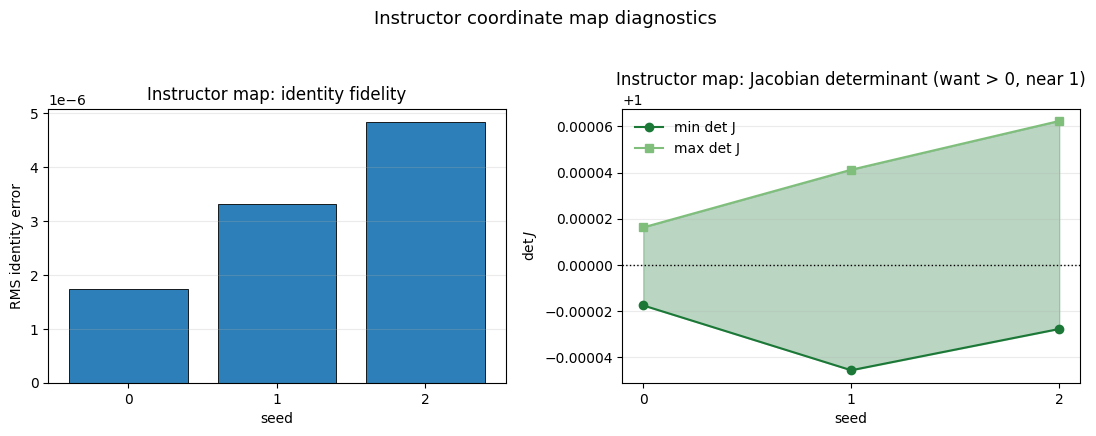

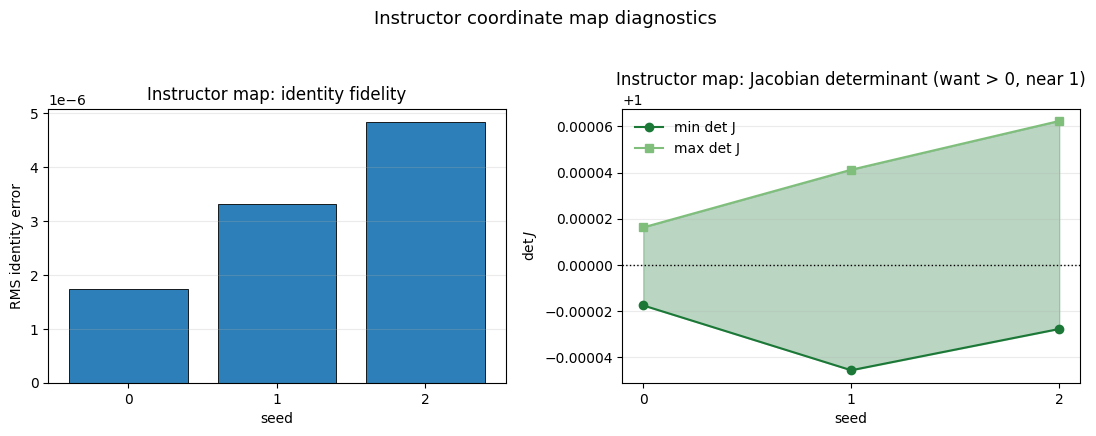

In [3]:
figures.plot_instructor_map_diagnostics()

**What it shows.** The instructor coordinate map maps coordinates to coordinates
and is trained toward the identity, so it has no shape gradient of its own.
Instead it is judged on map quality: left, the RMS identity error per seed
(should be near zero); right, the Jacobian determinant range per seed (should sit
at 1 with a low condition number).

**Result.** All three seeds give RMS identity error around 10^-6 with `det J = 1`
and condition number 1. The instructor map is a near-perfect, well-conditioned
identity. Crucially, this means the coordinate map is *not* the source of the
wrong-sign gradient seen above; the problem lives in the field network, not the
map.

## Step-count sweep

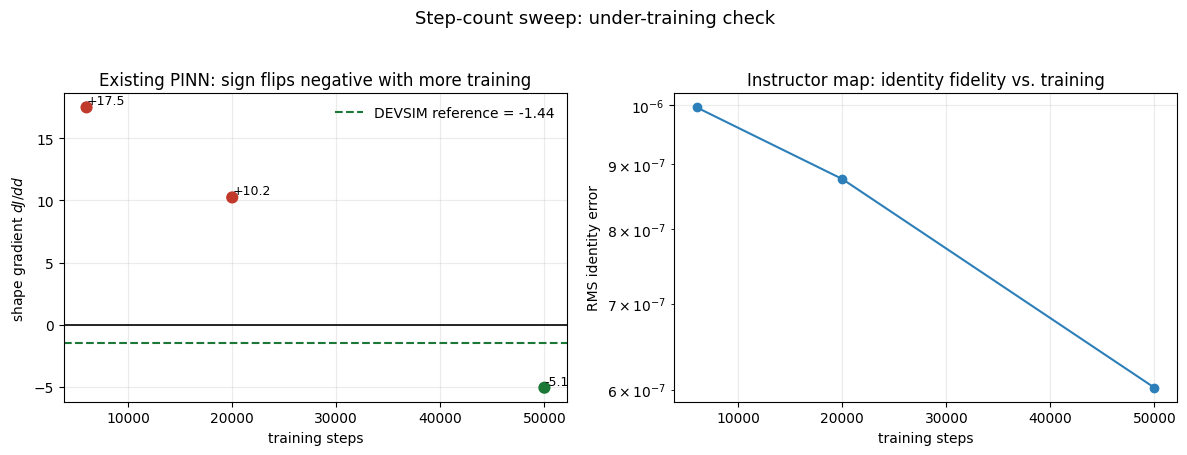

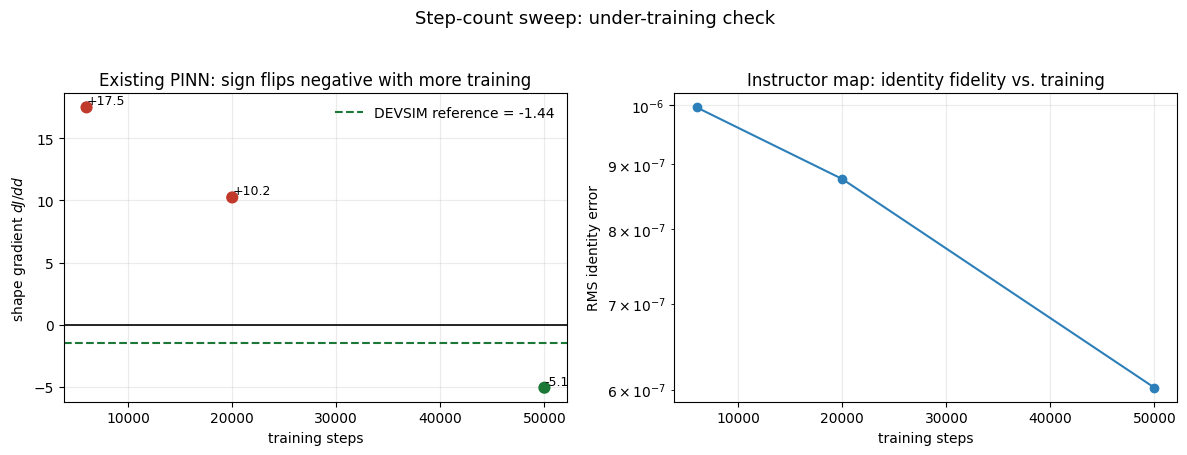

In [4]:
figures.plot_step_sweep()

**What it shows.** Left: the existing PINN's shape gradient `dJ/dd` at 6k, 20k,
and 50k training steps, against the DEVSIM reference (dashed green at -1.44).
Points are green if they have the correct (negative) sign, red otherwise. Right:
the instructor map's identity error versus training steps.

**Result, and the key finding.** The PINN gradient goes +17.5 -> +10.2 -> -5.07
as training increases, crossing zero to the **correct negative sign at 50k
steps**. So the wrong sign in the first plot was an under-training artifact, not
a fundamental flaw: with enough training the PINN recovers the right gradient
direction (its magnitude is still too large, so it needs more tuning to match).
The instructor map, by contrast, is already at ~10^-6 identity error at every
step count and does not change. Together with the previous plot, this localizes
the original failure to PINN field under-training, with the coordinate map
exonerated.